In [ ]:
import os, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, make_scorer)
from sklearn.base import clone
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve
import sklearn
warnings.filterwarnings("ignore")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [ ]:
import os

fname = "genai-burnout-risk-streamlit.csv"
print("Using:", fname, "| exists:", os.path.exists(fname))

Using: genai-burnout-risk-streamlit.csv | exists: True


In [ ]:
TARGET = "Burnout_Risk_Level"
SAMPLE_N = 10000        # None = use all rows (slower)
RS = 42

df = pd.read_csv(fname)
print("Raw shape:", df.shape)
display(df.head())
print(df.dtypes)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

# Drop ID-like columns (never float columns, which can be unique by chance)
id_cols = [c for c in df.columns if c != TARGET and
           (c.lower() in ("id", "student_id", "studentid", "index") or
            (df[c].nunique() == len(df) and not pd.api.types.is_float_dtype(df[c])))]
print("Dropping ID-like columns:", id_cols)

df = df.drop(columns=id_cols).drop_duplicates().dropna(subset=[TARGET])
if SAMPLE_N and len(df) > SAMPLE_N:
    df, _ = train_test_split(df, train_size=SAMPLE_N, stratify=df[TARGET], random_state=RS)
df = df.reset_index(drop=True)

X = df.drop(columns=[TARGET])
print(f"\nFeatures: {X.shape[1]} | Instances: {len(df)}")
assert X.shape[1] >= 12 and len(df) >= 500, "Dataset does not meet the minimum size"

Raw shape: (50000, 16)


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


Student_ID                      int64
Major_Category                 object
Year_of_Study                  object
Pre_Semester_GPA              float64
Weekly_GenAI_Hours            float64
Primary_Use_Case               object
Prompt_Engineering_Skill       object
Tool_Diversity                  int64
Paid_Subscription                bool
Traditional_Study_Hours       float64
Perceived_AI_Dependency         int64
Institutional_Policy           object
Anxiety_Level_During_Exams      int64
Post_Semester_GPA             float64
Skill_Retention_Score         float64
Burnout_Risk_Level             object
dtype: object

Missing values:
 Series([], dtype: int64)
Dropping ID-like columns: ['Student_ID']

Features: 14 | Instances: 10000


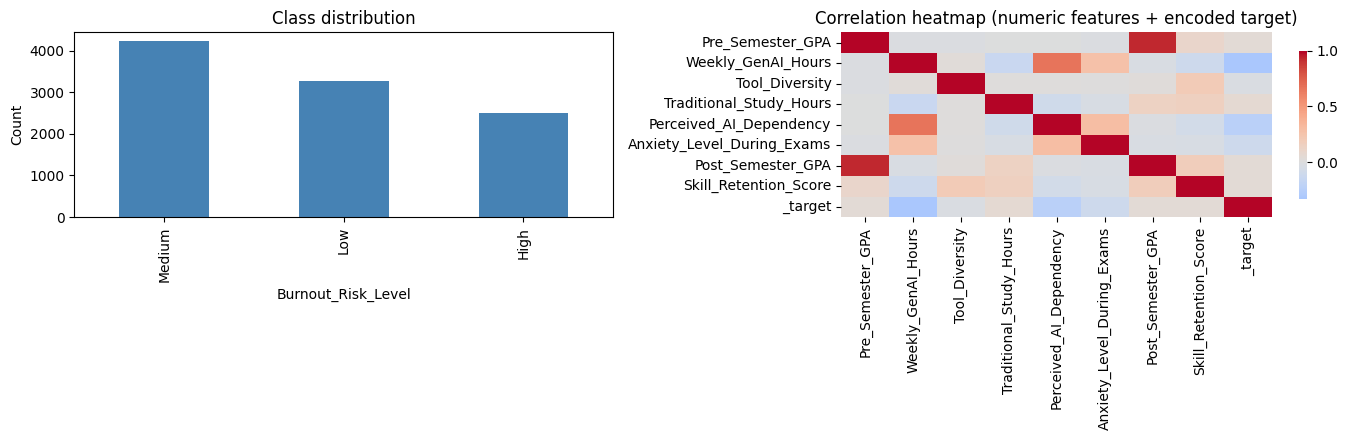

Top |correlation| with target:
Weekly_GenAI_Hours            0.328411
Perceived_AI_Dependency       0.238705
Anxiety_Level_During_Exams    0.113548
Traditional_Study_Hours       0.059374
Post_Semester_GPA             0.047546
Pre_Semester_GPA              0.043851
Skill_Retention_Score         0.042330
Tool_Diversity                0.023553
Name: _target, dtype: float64

Majority-class share: 0.423


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df[TARGET].value_counts().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Class distribution"); ax[0].set_ylabel("Count")

num_eda = df.select_dtypes(include=np.number)
tmp = num_eda.copy()
tmp["_target"] = LabelEncoder().fit_transform(df[TARGET])
corr = tmp.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .8})
ax[1].set_title("Correlation heatmap (numeric features + encoded target)")
plt.tight_layout(); plt.savefig("eda.png", dpi=120); plt.show()

print("Top |correlation| with target:")
print(corr["_target"].drop("_target").abs().sort_values(ascending=False).head(8))
print("\nMajority-class share:", round(df[TARGET].value_counts(normalize=True).max(), 3))
# If any feature has |corr| > 0.9 with the target, check for leakage.
# If all are near 0, the labels may be weakly related to the features (common in synthetic data).

In [ ]:
le = LabelEncoder()
y = le.fit_transform(df[TARGET])
class_names = list(le.classes_)
print("Classes:", class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

Classes: ['High', 'Low', 'Medium']
Numeric: 8 | Categorical: 6


In [ ]:
# (classifier, hyperparameter grid for tuning)

base = {
    "Logistic Regression":    (LogisticRegression(max_iter=1000, random_state=RS), {}),
    "Decision Tree":          (DecisionTreeClassifier(random_state=RS),
                               {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "KNN":                    (KNeighborsClassifier(), {"clf__n_neighbors": [3, 5, 11, 21]}),
    "Naive Bayes":            (GaussianNB(), {}),
    "Support Vector Machine": (SVC(kernel="rbf", random_state=RS), {"clf__C": [0.5, 1, 5]}),
}

def make_pipe(clf):
    return Pipeline([("prep", make_preprocessor()), ("clf", clone(clf))])

def evaluate(y_true, y_pred, y_proba):
    multi = len(np.unique(y_true)) > 2
    avg = "macro" if multi else "binary"
    auc = (roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro") if multi
           else roc_auc_score(y_true, y_proba[:, 1]))
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "AUC":       auc,
        "Precision": precision_score(y_true, y_pred, average=avg, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average=avg, zero_division=0),
        "F1":        f1_score(y_true, y_pred, average=avg, zero_division=0),
        "MCC":       matthews_corrcoef(y_true, y_pred),
    }

# Baseline: how well does always predicting the majority class do?
dummy = make_pipe(DummyClassifier(strategy="prior")).fit(X_train, y_train)
dres = evaluate(y_test, dummy.predict(X_test), dummy.predict_proba(X_test))
print("Baseline (majority class):", {k: round(v, 4) for k, v in dres.items()})

Baseline (majority class): {'Accuracy': 0.423, 'AUC': np.float64(0.5), 'Precision': 0.141, 'Recall': 0.3333, 'F1': 0.1982, 'MCC': 0.0}


Logistic Regression      acc 0.5290 ± 0.0101 | F1 0.5297 | MCC 0.2633
Decision Tree            acc 0.4301 ± 0.0120 | F1 0.4309 | MCC 0.1259
KNN                      acc 0.4439 ± 0.0062 | F1 0.4470 | MCC 0.1539
Naive Bayes              acc 0.5066 ± 0.0067 | F1 0.5105 | MCC 0.2553
Support Vector Machine   acc 0.5150 ± 0.0105 | F1 0.5083 | MCC 0.2366


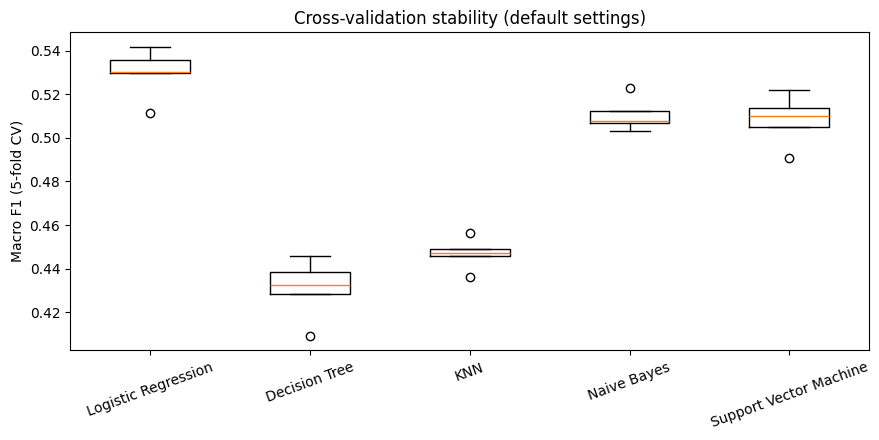

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scoring = {"acc": "accuracy", "f1": "f1_macro", "mcc": make_scorer(matthews_corrcoef)}

cv_scores = {}
for name, (clf, _) in base.items():
    out = cross_validate(make_pipe(clf), X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    cv_scores[name] = out
    print(f"{name:24s} acc {out['test_acc'].mean():.4f} ± {out['test_acc'].std():.4f} | "
          f"F1 {out['test_f1'].mean():.4f} | MCC {out['test_mcc'].mean():.4f}")

plt.figure(figsize=(9, 4.5))
plt.boxplot([cv_scores[n]["test_f1"] for n in base], labels=list(base), vert=True)
plt.xticks(rotation=20); plt.ylabel("Macro F1 (5-fold CV)")
plt.title("Cross-validation stability (default settings)")
plt.tight_layout(); plt.savefig("cv_boxplot.png", dpi=120); plt.show()

In [ ]:
best_params = {}
for name, (clf, grid) in base.items():
    if not grid:
        best_params[name] = {}
        continue
    gs = GridSearchCV(make_pipe(clf), grid, cv=3, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_params[name] = gs.best_params_
    print(f"{name:24s} best: {gs.best_params_} | CV macro-F1 {gs.best_score_:.4f}")

Decision Tree            best: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1} | CV macro-F1 0.5113
KNN                      best: {'clf__n_neighbors': 21} | CV macro-F1 0.4735
Support Vector Machine   best: {'clf__C': 0.5} | CV macro-F1 0.5088


In [ ]:
os.makedirs("model", exist_ok=True)
results, fitted = [], {}

for name, (clf, _) in base.items():
    pipe = make_pipe(clf).set_params(**best_params[name])
    if name == "Support Vector Machine":
        pipe.set_params(clf__probability=True)    # needed for AUC
    pipe.fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)
    results.append({"ML Model Name": name, **evaluate(y_test, pred, proba)})
    fitted[name] = pipe
    joblib.dump(pipe, f"model/{name.lower().replace(' ', '_')}.joblib")
    print("done:", name)

joblib.dump(le, "model/label_encoder.joblib")
joblib.dump({"num_cols": num_cols, "cat_cols": cat_cols,
             "target": TARGET, "class_names": class_names}, "model/meta.joblib")

res = pd.DataFrame(results).set_index("ML Model Name").round(4)
res.to_csv("results.csv")
display(res)
print("\nBaseline accuracy for reference:", round(dres["Accuracy"], 4))
print("Best by MCC:", res["MCC"].idxmax(), "| Best by Accuracy:", res["Accuracy"].idxmax())
print("\nMarkdown table for the README:\n")
print(res.reset_index().to_markdown(index=False))

done: Logistic Regression
done: Decision Tree
done: KNN
done: Naive Bayes
done: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.5420,0.7266,0.5708,0.5305,0.5429,0.2844
Decision Tree,0.5345,0.6996,0.5674,0.5164,0.5296,0.2699
KNN,0.4975,0.6670,0.5259,0.4891,0.5001,0.2161
Naive Bayes,0.5365,0.7126,0.5486,0.5495,0.5408,0.3018
Support Vector Machine,0.5455,0.7197,0.5972,0.5189,0.5332,0.2875



Baseline accuracy for reference: 0.423
Best by MCC: Naive Bayes | Best by Accuracy: Support Vector Machine

Markdown table for the README:

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.542  | 0.7266 |      0.5708 |   0.5305 | 0.5429 | 0.2844 |
| Decision Tree          |     0.5345 | 0.6996 |      0.5674 |   0.5164 | 0.5296 | 0.2699 |
| KNN                    |     0.4975 | 0.667  |      0.5259 |   0.4891 | 0.5001 | 0.2161 |
| Naive Bayes            |     0.5365 | 0.7126 |      0.5486 |   0.5495 | 0.5408 | 0.3018 |
| Support Vector Machine |     0.5455 | 0.7197 |      0.5972 |   0.5189 | 0.5332 | 0.2875 |


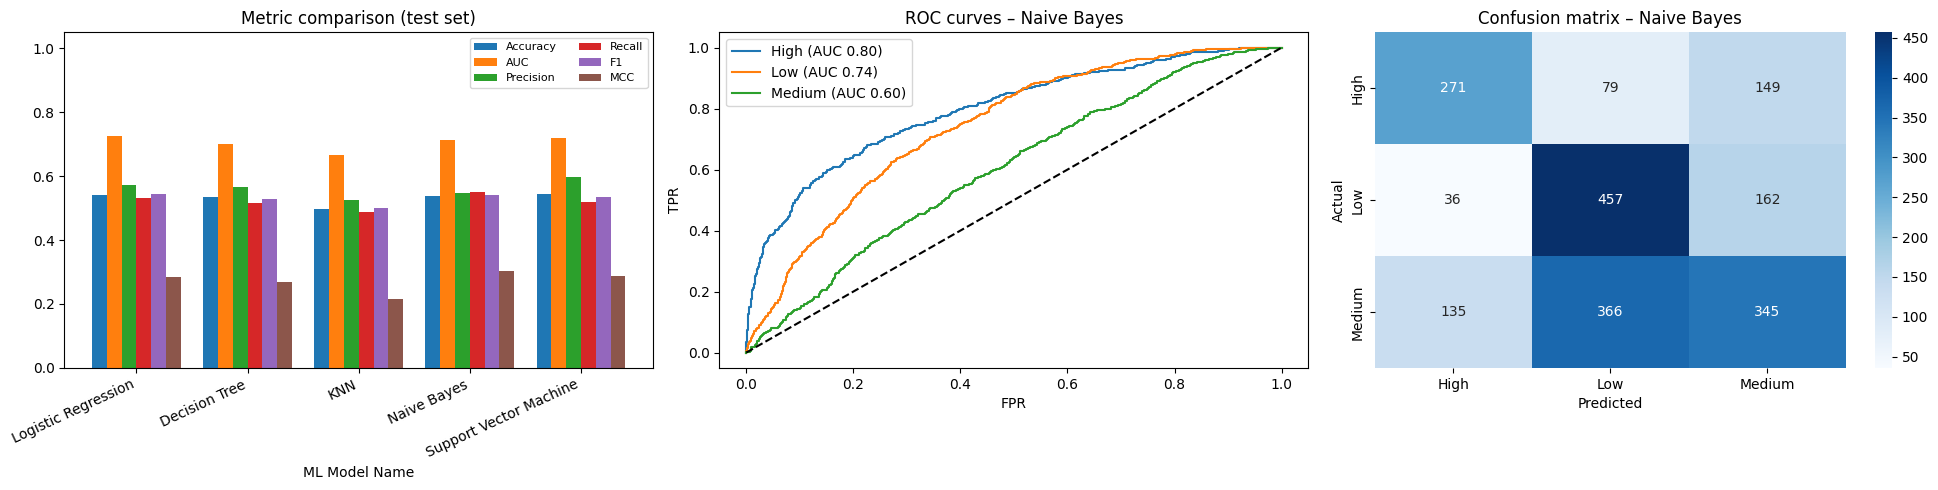

In [ ]:

best = res["MCC"].idxmax()
best_pipe = fitted[best]

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# 1) grouped bar chart of the 6 metrics
res.plot(kind="bar", ax=ax[0], width=0.8)
ax[0].set_title("Metric comparison (test set)"); ax[0].set_ylim(0, 1.05)
ax[0].set_xticklabels(res.index, rotation=25, ha="right"); ax[0].legend(fontsize=8, ncol=2)

# 2) ROC curves for the best model (one-vs-rest if multi-class)
proba = best_pipe.predict_proba(X_test)
if len(class_names) > 2:
    Yb = label_binarize(y_test, classes=range(len(class_names)))
    for i, cn in enumerate(class_names):
        fpr, tpr, _ = roc_curve(Yb[:, i], proba[:, i])
        ax[1].plot(fpr, tpr, label=f"{cn} (AUC {roc_auc_score(Yb[:, i], proba[:, i]):.2f})")
else:
    fpr, tpr, _ = roc_curve(y_test, proba[:, 1])
    ax[1].plot(fpr, tpr, label=f"AUC {roc_auc_score(y_test, proba[:, 1]):.2f}")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend()
ax[1].set_title(f"ROC curves – {best}"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")

# 3) confusion matrix for the best model
cm = confusion_matrix(y_test, best_pipe.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[2],
            xticklabels=class_names, yticklabels=class_names)
ax[2].set_title(f"Confusion matrix – {best}"); ax[2].set_xlabel("Predicted"); ax[2].set_ylabel("Actual")

plt.tight_layout(); plt.savefig("evaluation.png", dpi=120); plt.show()

In [ ]:
test_df = X_test.copy()
test_df[TARGET] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)
print("test_data.csv:", test_df.shape)

# Simulate exactly what the app will do: load a saved model and score the saved CSV
chk = joblib.load("model/support_vector_machine.joblib")
t = pd.read_csv("test_data.csv")
print("Reload check accuracy:",
      accuracy_score(le.transform(t[TARGET]), chk.predict(t.drop(columns=[TARGET]))))

!zip -r ml_assignment_files.zip model test_data.csv results.csv eda.png cv_boxplot.png evaluation.png
from google.colab import files
files.download("ml_assignment_files.zip")

test_data.csv: (2000, 15)
Reload check accuracy: 0.5455
  adding: model/ (stored 0%)
  adding: model/meta.joblib (deflated 27%)
  adding: model/label_encoder.joblib (deflated 34%)
  adding: model/support_vector_machine.joblib (deflated 80%)
  adding: model/decision_tree.joblib (deflated 58%)
  adding: model/naive_bayes.joblib (deflated 50%)
  adding: model/logistic_regression.joblib (deflated 54%)
  adding: model/knn.joblib (deflated 80%)
  adding: test_data.csv (deflated 81%)
  adding: results.csv (deflated 35%)
  adding: eda.png (deflated 16%)
  adding: cv_boxplot.png (deflated 16%)
  adding: evaluation.png (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>